# SER on CREMA-D: claimable evaluation vs. the 2026 SHAP/Permutation baseline

**What this notebook can and cannot support**
* It evaluates your pipeline on the **full** CREMA-D (7,442 clips, 91 actors) over **≥5 seeds**, in a **speaker-independent** setting (primary) and a random split (secondary).
* The baseline and the final model are scored on **identical test clips**, so differences are tested **paired**.
* The paper's 60.0 / 59.8 are only a **fixed published reference**. They were not re-run, their split/features are unverified, so no paired test against them is possible. The notebook reports a confidence interval for *our* score against that reference and prints the strongest wording the data allows.

**Protocol (fixed before running; do not change after seeing results)**
1. Primary comparison: final model vs reproduced baseline (XGBoost library defaults on the 296 handcrafted features), macro-F1, speaker-independent split, α = 0.05, Nadeau–Bengio corrected resampled t-test over seeds. Accuracy and the other comparisons are secondary; all p-values are Holm-corrected together.
2. Every choice (embedding layer, feature set, selector, k, classifier, hyper-parameters, MLP vs trees) is made on an inner validation split cut from the training part only. Test scores are only read out.
3. Uncertainty: per-seed mean ± std, corrected-t CI, actor-level paired bootstrap CI, exact McNemar per seed, sign count across seeds.
4. Added controls: a paper-style pipeline re-implemented on handcrafted features (SHAP / permutation top-k + XGBoost), and a representation-only model, so you can see *what* produces any gain.
5. The last cells run an automatic **claim gate** (full data, ≥5 seeds, primary mode run, paired predictions complete). If any check fails the report says NOT CLAIMABLE.

**Run order:** set `QUICK=False`, run all cells. The run is **resumable** (results and per-clip predictions are saved in `WORKDIR`; use `USE_DRIVE=True`). Rough, unmeasured estimate from the timings of your smoke run: several hours per mode on a T4, speaker mode first. Set `RUN_RANDOM=False` to roughly halve it.

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
!pip -q install kagglehub librosa soundfile xgboost lightgbm catboost optuna transformers scipy scikit-learn tqdm joblib

## Library (three module files)
`ser_lib.py` building blocks · `ser_stats.py` paired statistics · `ser_pipeline.py` experiment orchestration, saves per-clip test predictions.

In [12]:
%%writefile ser_lib.py
# -*- coding: utf-8 -*-
"""
SER on CREMA-D: reproducible experiment library.

Design rules (to avoid leakage):
  * The test split is used ONLY for the final reported numbers.
  * Every decision (embedding layer, feature set, selector, k, classifier,
    hyper-parameters) is made on an INNER validation split carved out of the
    training part only ("fit" / "val").
  * Every learned step (scaler, ranking, Boruta, mRMR, layer choice, Optuna)
    is fitted on training data only.
"""
import os, json, time, random, warnings, hashlib
from dataclasses import dataclass
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
CFG = dict(
    seeds=[42, 100, 2023, 7, 11],   # >=5 repeats are required for a claim
    test_size=0.30,
    inner_val_size=0.20,
    n_trials=20,              # Optuna budget (identical for every classifier)
    perm_repeats=2,
    boruta_iters=20,
    boruta_perc=90,
    boruta_alpha=0.05,
    mo_trials=25,             # NSGA-II trials for multi-objective selection
    k_grid=[32, 64, 128, 256, 512],
    shap_rows=2000,
    pooling="meanstd",        # "mean" or "meanstd"
    common_params=dict(n_estimators=300, learning_rate=0.1, max_depth=6),
    selector_estimators=150,
    use_gpu=True,
    fp16=True,
    emb_models={"w2v2": "facebook/wav2vec2-base", "wavlm": "microsoft/wavlm-base-plus"},
    # ---- reference + claim requirements
    paper=dict(acc=60.0, f1=59.8),   # published numbers (NOT re-run here)
    expected_files=7442,             # full CREMA-D
    min_seeds_for_claim=5,
    n_boot=2000,
)

EMOTION_MAP = {"SAD": "Sadness", "ANG": "Anger", "DIS": "Disgust",
               "FEA": "Fear", "HAP": "Happiness", "NEU": "Neutral"}


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except Exception:
        pass


def gpu_available():
    try:
        import torch
        return bool(torch.cuda.is_available()) and CFG["use_gpu"]
    except Exception:
        return False


# ----------------------------------------------------------------------------
# Data: parse + verify
# ----------------------------------------------------------------------------
def build_metadata(root):
    """Parse CREMA-D file names: <Actor>_<Sentence>_<Emotion>_<Intensity>.wav"""
    rows = []
    for dp, _, fs in os.walk(root):
        for f in fs:
            if f.lower().endswith(".wav"):
                p = f[:-4].split("_")
                if len(p) == 4 and p[2] in EMOTION_MAP:
                    rows.append(dict(filepath=os.path.join(dp, f), filename=f,
                                     actor_id=p[0], sentence_id=p[1],
                                     emotion_code=p[2], emotion=EMOTION_MAP[p[2]],
                                     intensity=p[3]))
    df = pd.DataFrame(rows).sort_values("filename").reset_index(drop=True)
    return df


def load_all_audio(paths, target_sr=16000, workers=8):
    """Load every wav once (threaded). Returns (list of float32 arrays, bad_idx)."""
    import soundfile as sf
    from concurrent.futures import ThreadPoolExecutor

    def _load(p):
        try:
            y, sr = sf.read(p, dtype="float32", always_2d=False)
            if y.ndim > 1:
                y = y.mean(axis=1)
            if sr != target_sr:
                import librosa
                y = librosa.resample(y, orig_sr=sr, target_sr=target_sr)
            if len(y) < 800 or not np.isfinite(y).all():
                return None
            return y.astype(np.float32)
        except Exception:
            return None

    with ThreadPoolExecutor(workers) as ex:
        out = list(ex.map(_load, paths))
    bad = [i for i, a in enumerate(out) if a is None]
    return out, bad


# ----------------------------------------------------------------------------
# Handcrafted features (296 = same composition as the notebook)
# ----------------------------------------------------------------------------
def _stats(m):
    return np.hstack([m.mean(1), m.std(1), m.min(1), m.max(1)])


def handcrafted_from_wave(y, sr=16000):
    """MFCC20 + chroma12 + contrast7 + RMS + ZCR + mel33, x4 stats = 296 dims.
    STFT is computed once and shared (≈3x faster than calling librosa per feature)."""
    import librosa
    S = np.abs(librosa.stft(y, n_fft=2048, hop_length=512)).astype(np.float32)
    P = S ** 2
    mel128 = librosa.feature.melspectrogram(S=P, sr=sr, n_mels=128)
    mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel128), n_mfcc=20)
    chroma = librosa.feature.chroma_stft(S=P, sr=sr, n_chroma=12)
    contrast = librosa.feature.spectral_contrast(S=S, sr=sr, n_bands=6)
    rms = librosa.feature.rms(y=y)
    zcr = librosa.feature.zero_crossing_rate(y)
    mel33 = librosa.feature.melspectrogram(S=P, sr=sr, n_mels=33)
    f = np.hstack([_stats(mfcc), _stats(chroma), _stats(contrast),
                   _stats(rms), _stats(zcr), _stats(mel33)])
    return f.astype(np.float32)


def extract_handcrafted(wavs, n_jobs=-1):
    from joblib import Parallel, delayed
    feats = Parallel(n_jobs=n_jobs, batch_size=64)(delayed(handcrafted_from_wave)(w) for w in wavs)
    X = np.vstack(feats)
    assert X.shape[1] == 296, X.shape
    return np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)


# ----------------------------------------------------------------------------
# Pretrained embeddings (Wav2Vec2 / WavLM): all layers, masked mean(+std) pooling,
# length-sorted dynamic batching, fp16. One pass -> every layer is cached.
# ----------------------------------------------------------------------------
def extract_embeddings(model_name, wavs, max_batch_samples=16000 * 90, fp16=True, pooling="meanstd"):
    import torch
    from transformers import AutoFeatureExtractor, AutoModel
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    fe = AutoFeatureExtractor.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(dev).eval()
    do_norm = bool(getattr(fe, "do_normalize", True))
    use_mask = bool(getattr(fe, "return_attention_mask", False))
    amp = bool(fp16 and dev.type == "cuda")

    order = np.argsort([len(w) for w in wavs])
    N = len(wavs)
    L = model.config.num_hidden_layers + 1
    D = model.config.hidden_size
    out = np.zeros((N, L, D * (2 if pooling == "meanstd" else 1)), dtype=np.float16)

    batches, cur, cur_max = [], [], 0
    for i in order:
        m = max(cur_max, len(wavs[i]))
        if cur and m * (len(cur) + 1) > max_batch_samples:
            batches.append(cur); cur, m = [], len(wavs[i])
        cur.append(i); cur_max = m
    if cur:
        batches.append(cur)

    from tqdm.auto import tqdm
    with torch.no_grad():
        for b in tqdm(batches, desc=f"embeddings {model_name.split('/')[-1]}"):
            lens = np.array([len(wavs[i]) for i in b])
            T = lens.max()
            x = np.zeros((len(b), T), dtype=np.float32)
            for r, i in enumerate(b):
                w = wavs[i]
                if do_norm:
                    w = (w - w.mean()) / np.sqrt(w.var() + 1e-7)
                x[r, :len(w)] = w
            x = torch.from_numpy(x).to(dev)
            am = torch.zeros_like(x, dtype=torch.long)
            for r, ln in enumerate(lens):
                am[r, :ln] = 1
            with torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=amp):
                kw = dict(attention_mask=am) if use_mask else {}
                hs = model(x, output_hidden_states=True, **kw).hidden_states
            flen = model._get_feat_extract_output_lengths(torch.from_numpy(lens)).to(dev)
            Tf = hs[0].shape[1]
            fmask = (torch.arange(Tf, device=dev)[None, :] < flen[:, None]).float().unsqueeze(-1)  # B,Tf,1
            denom = fmask.sum(1).clamp(min=1)
            feats = []
            for h in hs:
                h = h.float()
                mu = (h * fmask).sum(1) / denom
                if pooling == "meanstd":
                    var = (((h - mu[:, None, :]) ** 2) * fmask).sum(1) / denom
                    feats.append(torch.cat([mu, torch.sqrt(var + 1e-6)], dim=-1))
                else:
                    feats.append(mu)
            f = torch.stack(feats, dim=1).cpu().numpy().astype(np.float16)  # B,L,D'
            out[b] = f
    del model
    if dev.type == "cuda":
        torch.cuda.empty_cache()
    return out


# ----------------------------------------------------------------------------
# Splits
# ----------------------------------------------------------------------------
@dataclass
class Split:
    seed: int
    mode: str
    tr: np.ndarray
    te: np.ndarray
    fit: np.ndarray   # inner-train (subset of tr)
    val: np.ndarray   # inner-validation (subset of tr)


def make_split(y, actors, seed, mode="random", test_size=None, inner=None):
    from sklearn.model_selection import train_test_split, GroupShuffleSplit
    test_size = test_size or CFG["test_size"]
    inner = inner or CFG["inner_val_size"]
    idx = np.arange(len(y))
    if mode == "random":
        tr, te = train_test_split(idx, test_size=test_size, random_state=seed, stratify=y)
        fit, val = train_test_split(tr, test_size=inner, random_state=seed, stratify=y[tr])
    elif mode == "speaker":
        g = np.asarray(actors)
        tr, te = next(GroupShuffleSplit(1, test_size=test_size, random_state=seed).split(idx, y, g))
        a, b = next(GroupShuffleSplit(1, test_size=inner, random_state=seed).split(tr, y[tr], g[tr]))
        fit, val = tr[a], tr[b]
        assert not set(g[tr]) & set(g[te]), "speaker overlap between train and test!"
        assert not set(g[fit]) & set(g[val]), "speaker overlap between fit and val!"
    else:
        raise ValueError(mode)
    return Split(seed, mode, np.sort(tr), np.sort(te), np.sort(fit), np.sort(val))


# ----------------------------------------------------------------------------
# Classifiers
# ----------------------------------------------------------------------------
def make_clf(name, seed, params=None, library_defaults=False, n_jobs=-1):
    """name in {xgb, lgbm, cat}. library_defaults=True -> untouched library defaults
    (used only to reproduce the baseline). Otherwise a common budget is used so the
    three classifiers are compared under the same conditions."""
    gpu = gpu_available()
    p = {} if library_defaults else dict(CFG["common_params"])
    if params:
        p.update(params)
    if name == "xgb":
        from xgboost import XGBClassifier
        kw = dict(random_state=seed, tree_method="hist", eval_metric="mlogloss", verbosity=0)
        kw["device"] = "cuda" if gpu else "cpu"
        if not gpu:
            kw["n_jobs"] = n_jobs
        kw.update(p)
        return XGBClassifier(**kw)
    if name == "lgbm":
        from lightgbm import LGBMClassifier
        q = dict(p)
        if not library_defaults:
            depth = q.pop("max_depth", 6)                 # same capacity as depth-6 trees
            q.setdefault("num_leaves", 2 ** min(depth, 7) - 1)
        return LGBMClassifier(random_state=seed, n_jobs=n_jobs, verbose=-1,
                              force_col_wise=True, **q)
    if name == "cat":
        from catboost import CatBoostClassifier
        q = {}
        for k, v in p.items():
            q[{"n_estimators": "iterations", "max_depth": "depth"}.get(k, k)] = v
        kw = dict(random_seed=seed, verbose=0, loss_function="MultiClass", allow_writing_files=False)
        if gpu:
            kw["task_type"] = "GPU"
        else:
            kw["thread_count"] = n_jobs
        kw.update(q)
        return CatBoostClassifier(**kw)
    raise ValueError(name)


def score(y_true, y_pred):
    from sklearn.metrics import accuracy_score, f1_score
    return dict(acc=float(accuracy_score(y_true, y_pred)),
                f1=float(f1_score(y_true, y_pred, average="macro")))


def fit_eval(name, Xa, ya, Xb, yb, seed, params=None, library_defaults=False):
    clf = make_clf(name, seed, params, library_defaults)
    clf.fit(Xa, ya)
    pred = np.asarray(clf.predict(Xb)).ravel().astype(int)
    return score(yb, pred), clf


# ----------------------------------------------------------------------------
# Embedding layer choice (inner split only) -> feature matrices
# ----------------------------------------------------------------------------
def choose_layer(E, y, split, seed):
    """Pick the best transformer layer with a fast closed-form ridge classifier,
    fitted on `fit` and scored on `val` (never touches test)."""
    from sklearn.linear_model import RidgeClassifier
    from sklearn.preprocessing import StandardScaler
    scores = []
    for l in range(E.shape[1]):
        A = E[split.fit, l].astype(np.float32); B = E[split.val, l].astype(np.float32)
        sc = StandardScaler().fit(A)
        m = RidgeClassifier(alpha=100.0).fit(sc.transform(A), y[split.fit])
        scores.append(score(y[split.val], m.predict(sc.transform(B)))["f1"])
    return int(np.argmax(scores)), scores


# ----------------------------------------------------------------------------
# Importance / ranking methods  (all take SELECTION data only)
# ----------------------------------------------------------------------------
def _selector_xgb(seed, n_est=None):
    return make_clf("xgb", seed, dict(n_estimators=n_est or CFG["selector_estimators"],
                                      learning_rate=0.1, max_depth=6, colsample_bytree=0.5))


def shap_importance(X, y, seed):
    """Mean |SHAP| (TreeSHAP, exact, via XGBoost pred_contribs) across rows & classes.
    Same algorithm as shap.TreeExplainer but runs natively on GPU."""
    import xgboost as xgb
    m = _selector_xgb(seed).fit(X, y)
    rng = np.random.RandomState(seed)
    rows = rng.choice(len(X), min(CFG["shap_rows"], len(X)), replace=False)
    contrib = m.get_booster().predict(xgb.DMatrix(X[rows]), pred_contribs=True)
    contrib = np.asarray(contrib)
    if contrib.ndim == 3:                       # (n, classes, feats+1)
        imp = np.abs(contrib[:, :, :-1]).mean(axis=(0, 1))
    else:
        imp = np.abs(contrib[:, :-1]).mean(axis=0)
    return imp


def permutation_importance_rank(X, y, seed, repeats=None):
    """Permutation importance (macro-F1 drop) on a held-out 20% of SELECTION data.

    Uses sklearn's joblib-parallel implementation rather than a Python loop over
    every feature. The estimator, validation subset, scoring rule and number of
    repeats are unchanged; only independent feature permutations are parallelized.
    """
    from sklearn.model_selection import train_test_split
    from sklearn.inspection import permutation_importance
    repeats = repeats or CFG["perm_repeats"]
    a, b = train_test_split(np.arange(len(y)), test_size=0.2,
                            random_state=seed, stratify=y)
    m = _selector_xgb(seed).fit(X[a], y[a])
    result = permutation_importance(
        m, X[b], y[b],
        scoring="f1_macro",
        n_repeats=repeats,
        random_state=seed,
        # Avoid spawning multiple processes against one CUDA-backed estimator.
        n_jobs=1 if gpu_available() else -1,
    )
    return np.asarray(result.importances_mean, dtype=np.float64)


def mrmr_rank(X, y, k_max=512, scheme="fcq"):
    """Greedy mRMR. relevance = ANOVA F, redundancy = mean |Pearson corr| with the
    already selected features. scheme: 'fcq' (F / red) or 'fcd' (F - red)."""
    from sklearn.feature_selection import f_classif
    F, _ = f_classif(X, y)
    F = np.nan_to_num(F)
    rel = F / (F.max() + 1e-12)
    Z = (X - X.mean(0)) / (X.std(0) + 1e-8)
    p = X.shape[1]; k_max = min(k_max, p)
    sel = [int(np.argmax(rel))]
    red_sum = np.abs(Z.T @ Z[:, sel[0]]) / len(Z)
    taken = np.zeros(p, bool); taken[sel[0]] = True
    for t in range(1, k_max):
        red = red_sum / t
        score_ = rel / (red + 1e-3) if scheme == "fcq" else rel - red
        score_[taken] = -np.inf
        j = int(np.argmax(score_))
        sel.append(j); taken[j] = True
        red_sum += np.abs(Z.T @ Z[:, j]) / len(Z)
    return np.array(sel)


def boruta_shap(X, y, seed, n_iter=None, perc=None, alpha=None, min_keep=20):
    """Boruta with SHAP importances. Each iteration: add column-permuted 'shadow'
    copies, fit a light XGBoost, compare each real feature's mean|SHAP| with the
    perc-th percentile of shadow importances, count hits, binomial test with
    Bonferroni correction. Returns (selected_idx, hits, status)."""
    import xgboost as xgb
    from scipy.stats import binom
    n_iter = n_iter or CFG["boruta_iters"]; perc = perc or CFG["boruta_perc"]
    alpha = alpha or CFG["boruta_alpha"]
    rng = np.random.RandomState(seed)
    n, p = X.shape
    hits = np.zeros(p, int)
    status = np.zeros(p, int)           # 0 tentative, 1 confirmed, -1 rejected
    it_done = 0
    for it in range(1, n_iter + 1):
        act = np.where(status >= 0)[0]
        if len(act) == 0:
            break
        Xa = X[:, act]
        Xs = np.apply_along_axis(rng.permutation, 0, Xa)
        Xc = np.hstack([Xa, Xs]).astype(np.float32)
        m = make_clf("xgb", seed + it, dict(n_estimators=80, learning_rate=0.2, max_depth=4,
                                            colsample_bytree=0.5, subsample=0.7)).fit(Xc, y)
        rows = rng.choice(n, min(800, n), replace=False)
        c = np.asarray(m.get_booster().predict(xgb.DMatrix(Xc[rows]), pred_contribs=True))
        imp = np.abs(c[:, :, :-1]).mean(axis=(0, 1)) if c.ndim == 3 else np.abs(c[:, :-1]).mean(0)
        thr = np.percentile(imp[len(act):], perc)
        hits[act] += (imp[:len(act)] > thr).astype(int)
        it_done = it
        und = np.where(status == 0)[0]
        if len(und) and it >= 5:
            a_c = alpha / len(und)
            p_hi = binom.sf(hits[und] - 1, it, 0.5)
            p_lo = binom.cdf(hits[und], it, 0.5)
            status[und[p_hi < a_c]] = 1
            status[und[p_lo < a_c]] = -1
    sel = np.where(status == 1)[0]
    if len(sel) < min_keep:                    # fallback: top by hit count (tie -> index)
        sel = np.argsort(-hits, kind="stable")[:min_keep]
    return np.sort(sel), hits, status


def multiobjective_shap_mrmr(X, y, seed, n_trials=None, k_max=512):
    """Multi-objective selection (NSGA-II over lambda and k).
       maximise: macro-F1 on an internal validation split
       minimise: number of features, mean |corr| inside the subset (redundancy)
    Greedy order for each lambda: argmax  SHAPrel_j - lambda * mean|corr(j, S)|."""
    import optuna
    from sklearn.model_selection import train_test_split
    n_trials = n_trials or CFG["mo_trials"]
    a, b = train_test_split(np.arange(len(y)), test_size=0.25, random_state=seed, stratify=y)
    imp = shap_importance(X[a], y[a], seed)
    rel = imp / (imp.max() + 1e-12)
    Z = (X[a] - X[a].mean(0)) / (X[a].std(0) + 1e-8)
    C = np.abs(Z.T @ Z) / len(Z)
    p = X.shape[1]; k_max = min(k_max, p)

    def greedy(lam):
        sel = [int(np.argmax(rel))]; taken = np.zeros(p, bool); taken[sel[0]] = True
        red_sum = C[:, sel[0]].copy()
        for t in range(1, k_max):
            s = rel - lam * red_sum / t
            s[taken] = -np.inf
            j = int(np.argmax(s)); sel.append(j); taken[j] = True
            red_sum += C[:, j]
        return np.array(sel)

    cache = {}
    def objective(trial):
        lam = trial.suggest_float("lam", 0.0, 2.0)
        k = trial.suggest_int("k", 16, k_max)
        key = round(lam, 6)
        if key not in cache:
            cache[key] = greedy(lam)
        idx = cache[key][:k]
        m = make_clf("xgb", seed, dict(n_estimators=100, learning_rate=0.15, max_depth=6)).fit(X[a][:, idx], y[a])
        f1 = score(y[b], m.predict(X[b][:, idx]))["f1"]
        sub = C[np.ix_(idx, idx)]
        red = float((sub.sum() - np.trace(sub)) / max(1, len(idx) * (len(idx) - 1)))
        return f1, float(len(idx)), red

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    st = optuna.create_study(directions=["maximize", "minimize", "minimize"],
                             sampler=optuna.samplers.NSGAIISampler(seed=seed, population_size=10))
    st.optimize(objective, n_trials=n_trials)
    front = st.best_trials
    best_f1 = max(t.values[0] for t in front)
    ok = [t for t in front if t.values[0] >= best_f1 - 0.005]
    ok.sort(key=lambda t: (t.values[1], t.values[2]))
    t = ok[0]
    # the greedy order used in the chosen trial was built on rows `a` only -> recompute
    # on the full selection data so that the final set uses all selection samples
    imp_full = shap_importance(X, y, seed)
    rel_full = imp_full / (imp_full.max() + 1e-12)
    Zf = (X - X.mean(0)) / (X.std(0) + 1e-8)
    Cf = np.abs(Zf.T @ Zf) / len(Zf)
    lam = t.params["lam"]; k = t.params["k"]
    sel = [int(np.argmax(rel_full))]; taken = np.zeros(p, bool); taken[sel[0]] = True
    red_sum = Cf[:, sel[0]].copy()
    for s_ in range(1, min(k, p)):
        s = rel_full - lam * red_sum / s_
        s[taken] = -np.inf
        j = int(np.argmax(s)); sel.append(j); taken[j] = True
        red_sum += Cf[:, j]
    info = dict(lam=lam, k=int(k), pareto=[(tt.values[0], tt.values[1], tt.values[2]) for tt in front])
    return np.array(sel), info


# ----------------------------------------------------------------------------
# MLP + Integrated Gradients (only valid for differentiable models)
# ----------------------------------------------------------------------------
def fit_mlp(X, y, seed, epochs=80, lr=1e-3, wd=1e-4, patience=12, hidden=(512, 256), drop=0.3):
    import torch, torch.nn as nn
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    set_seed(seed)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    a, b = train_test_split(np.arange(len(y)), test_size=0.1, random_state=seed, stratify=y)
    sc = StandardScaler().fit(X[a])
    Xa = torch.tensor(sc.transform(X[a]), dtype=torch.float32, device=dev)
    Xb = torch.tensor(sc.transform(X[b]), dtype=torch.float32, device=dev)
    ya = torch.tensor(y[a], dtype=torch.long, device=dev)
    yb = torch.tensor(y[b], dtype=torch.long, device=dev)
    layers, d = [], X.shape[1]
    for h in hidden:
        layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(drop)]; d = h
    layers.append(nn.Linear(d, int(y.max()) + 1))
    net = nn.Sequential(*layers).to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    lossf = nn.CrossEntropyLoss(label_smoothing=0.05)
    best, best_state, bad = -1, None, 0
    g = torch.Generator(device="cpu").manual_seed(seed)
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(Xa), generator=g).to(dev)
        for i in range(0, len(perm), 128):
            ix = perm[i:i + 128]
            if len(ix) < 2:
                continue
            opt.zero_grad(); lossf(net(Xa[ix]), ya[ix]).backward(); opt.step()
        sched.step(); net.eval()
        with torch.no_grad():
            acc = (net(Xb).argmax(1) == yb).float().mean().item()
        if acc > best:
            best, bad = acc, 0
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state); net.eval()
    return net, sc, dev


def mlp_predict(net, sc, dev, X):
    import torch
    with torch.no_grad():
        out = net(torch.tensor(sc.transform(X), dtype=torch.float32, device=dev))
    return out.argmax(1).cpu().numpy()


def integrated_gradients_importance(net, sc, dev, X, steps=24, max_rows=1500, seed=0):
    """Mean |IG| per feature w.r.t. the predicted-class logit, zero baseline in the
    standardised space (= training mean). Riemann-midpoint rule."""
    import torch
    rng = np.random.RandomState(seed)
    rows = rng.choice(len(X), min(max_rows, len(X)), replace=False)
    x = torch.tensor(sc.transform(X[rows]), dtype=torch.float32, device=dev)
    with torch.no_grad():
        tgt = net(x).argmax(1)
    total = torch.zeros_like(x)
    for s in range(steps):
        a = (s + 0.5) / steps
        xi = (a * x).clone().requires_grad_(True)
        logit = net(xi).gather(1, tgt[:, None]).sum()
        g, = torch.autograd.grad(logit, xi)
        total += g
    ig = x * total / steps
    return ig.abs().mean(0).cpu().numpy()


# ----------------------------------------------------------------------------
# Optuna (same budget, same sampler, same inner split for every classifier)
# ----------------------------------------------------------------------------
def search_space(name, trial):
    if name == "xgb":
        return dict(n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                    learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
                    max_depth=trial.suggest_int("max_depth", 3, 9),
                    subsample=trial.suggest_float("subsample", 0.5, 1.0),
                    colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
                    min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
                    reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
                    reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
                    gamma=trial.suggest_float("gamma", 0.0, 3.0))
    if name == "lgbm":
        return dict(n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                    learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
                    num_leaves=trial.suggest_int("num_leaves", 15, 127),
                    min_child_samples=trial.suggest_int("min_child_samples", 5, 50),
                    subsample=trial.suggest_float("subsample", 0.5, 1.0),
                    subsample_freq=1,
                    colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
                    reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
                    reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True))
    if name == "cat":
        return dict(n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                    learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
                    max_depth=trial.suggest_int("max_depth", 4, 9),
                    l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0, log=True),
                    random_strength=trial.suggest_float("random_strength", 0.1, 5.0, log=True))
    raise ValueError(name)


def tune(name, Xa, ya, Xb, yb, seed, n_trials=None):
    """Optimise macro-F1 on (Xb,yb), which must be an inner-validation set built from
    training data only. Returns best params and best val F1."""
    import optuna
    n_trials = n_trials or CFG["n_trials"]
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def obj(trial):
        params = search_space(name, trial)
        return fit_eval(name, Xa, ya, Xb, yb, seed, params)[0]["f1"]

    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
    st.optimize(obj, n_trials=n_trials)
    best = dict(st.best_params)
    if name == "lgbm":
        best["subsample_freq"] = 1
    return best, float(st.best_value)


# ----------------------------------------------------------------------------
# Results store (resumable on Colab)
# ----------------------------------------------------------------------------
class Store:
    def __init__(self, path):
        self.path = path
        self.rows = json.load(open(path)) if os.path.exists(path) else []

    def has(self, key):
        return any(r["key"] == key for r in self.rows)

    def get(self, key):
        for r in self.rows:
            if r["key"] == key:
                return r
        return None

    def add(self, row):
        self.rows = [r for r in self.rows if r["key"] != row["key"]]
        self.rows.append(row)
        json.dump(self.rows, open(self.path, "w"), indent=1, default=float)

    def df(self):
        return pd.DataFrame(self.rows)

Overwriting ser_lib.py


In [13]:
%%writefile ser_stats.py
# -*- coding: utf-8 -*-
"""
Statistics for a credible model comparison on repeated splits.

Why these tests
---------------
* Baseline and improved model are evaluated on the SAME test clips of the SAME split
  -> paired analysis (McNemar, paired bootstrap, paired differences across seeds).
* CREMA-D clips of one actor are correlated -> the bootstrap resamples ACTORS (clusters),
  not clips.
* Seeds re-use the same recordings, so per-seed scores are not independent.
  The Nadeau-Bengio corrected resampled t-test inflates the variance by (1/k + n_test/n_train)
  to account for this (a plain t-test over seeds is anti-conservative).
* Comparison with the paper uses its published numbers as a fixed reference: no paired test
  is possible, only a confidence interval for our model against that reference.
"""
import numpy as np
import pandas as pd
from scipy import stats


# ----------------------------------------------------------------------------- metrics
def _cm_by_group(y, p, groups, n_cls):
    ug, inv = np.unique(groups, return_inverse=True)
    cm = np.zeros((len(ug), n_cls, n_cls), dtype=np.float64)
    np.add.at(cm, (inv, np.asarray(y, int), np.asarray(p, int)), 1.0)
    return cm                                           # [group, true, pred]


def _macro_f1(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    fp = cm.sum(-2) - tp
    fn = cm.sum(-1) - tp
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros_like(den), where=den > 0)
    return f1.mean(-1)


def _acc(cm):
    return np.trace(cm, axis1=-2, axis2=-1) / cm.sum(axis=(-2, -1))


def metrics(y, p, n_cls):
    cm = _cm_by_group(y, p, np.zeros(len(y)), n_cls).sum(0)
    return dict(acc=float(_acc(cm)), f1=float(_macro_f1(cm)))


# ----------------------------------------------------------------------------- tests
def mcnemar_exact(y, p_base, p_new):
    """Exact McNemar on one test set. Treats clips as independent (descriptive only)."""
    cb, cn = (np.asarray(p_base) == y), (np.asarray(p_new) == y)
    b = int((cb & ~cn).sum()); c = int((~cb & cn).sum()); n = b + c
    p = 1.0 if n == 0 else float(stats.binomtest(min(b, c), n, 0.5).pvalue)
    return dict(base_only_correct=b, new_only_correct=c, p=p)


def corrected_resampled_ttest(d, n_train, n_test, level=0.95):
    """Nadeau & Bengio (2003) corrected resampled t-test on per-seed differences d."""
    d = np.asarray(d, float); k = len(d)
    mean = float(d.mean())
    if k < 2:
        return dict(mean=mean, sd=np.nan, se=np.nan, t=np.nan, df=0, p=np.nan, lo=np.nan, hi=np.nan, k=k)
    var = float(d.var(ddof=1))
    se = float(np.sqrt((1.0 / k + n_test / n_train) * var))
    df = k - 1
    if se == 0:
        p = 0.0 if mean != 0 else 1.0
        return dict(mean=mean, sd=0.0, se=0.0, t=np.inf if mean else 0.0, df=df, p=p, lo=mean, hi=mean, k=k)
    t = mean / se
    p = float(2 * stats.t.sf(abs(t), df))
    h = float(stats.t.ppf(0.5 + level / 2, df) * se)
    return dict(mean=mean, sd=float(np.sqrt(var)), se=se, t=float(t), df=df, p=p, lo=mean - h, hi=mean + h, k=k)


def vs_reference(values, ref, n_train, n_test, level=0.95):
    """Our per-seed scores against a fixed published number (descriptive; protocols may differ)."""
    r = corrected_resampled_ttest(np.asarray(values, float) - ref, n_train, n_test, level)
    out = dict(mean=ref + r["mean"], lo=max(0.0, ref + r["lo"]), hi=min(100.0, ref + r["hi"]), diff=r["mean"],
               diff_lo=r["lo"], diff_hi=r["hi"], p=r["p"], k=r["k"], sd=r["sd"])
    out["verdict"] = ("above" if out["diff_lo"] > 0 else "below" if out["diff_hi"] < 0 else "not distinguishable")
    return out


def holm(pvals):
    p = np.asarray(pvals, float); m = len(p)
    order = np.argsort(p); adj = np.empty(m)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def paired_cluster_bootstrap(pairs, n_cls, n_boot=2000, seed=0, level=0.95):
    """Actor-level paired bootstrap inside each seed's test set; every replicate averages the
    per-seed delta over seeds.  Captures test-sample uncertainty (not training variability)."""
    rng = np.random.default_rng(seed)
    prep = [(_cm_by_group(d["y"], d["p_base"], d["groups"], n_cls),
             _cm_by_group(d["y"], d["p_new"], d["groups"], n_cls)) for d in pairs]
    da = np.zeros(n_boot); df = np.zeros(n_boot)
    for b in range(n_boot):
        sa = sf = 0.0
        for cb, cn in prep:
            G = len(cb)
            w = np.bincount(rng.integers(0, G, G), minlength=G).astype(float)
            sb = np.tensordot(w, cb, axes=(0, 0)); sn = np.tensordot(w, cn, axes=(0, 0))
            sa += _acc(sn) - _acc(sb); sf += _macro_f1(sn) - _macro_f1(sb)
        da[b], df[b] = sa / len(prep), sf / len(prep)
    q = [(1 - level) / 2 * 100, (1 + level) / 2 * 100]
    return dict(acc=tuple(np.percentile(da, q)), f1=tuple(np.percentile(df, q)))


def compare(pairs, n_cls, n_boot=2000, seed=0, level=0.95):
    """pairs: list of dict(seed,y,groups,p_base,p_new,n_train,n_test) -> per-seed table + summary."""
    rows = []
    for d in pairs:
        mb = metrics(d["y"], d["p_base"], n_cls); mn = metrics(d["y"], d["p_new"], n_cls)
        mc = mcnemar_exact(d["y"], d["p_base"], d["p_new"])
        rows.append(dict(seed=d["seed"], n_test=len(d["y"]),
                         base_acc=mb["acc"] * 100, new_acc=mn["acc"] * 100, d_acc=(mn["acc"] - mb["acc"]) * 100,
                         base_f1=mb["f1"] * 100, new_f1=mn["f1"] * 100, d_f1=(mn["f1"] - mb["f1"]) * 100,
                         mcnemar_p=mc["p"], base_only=mc["base_only_correct"], new_only=mc["new_only_correct"]))
    per = pd.DataFrame(rows)
    n_tr = float(np.mean([d["n_train"] for d in pairs])); n_te = float(np.mean([d["n_test"] for d in pairs]))
    boot = paired_cluster_bootstrap(pairs, n_cls, n_boot, seed, level)
    summ = {}
    for m in ["acc", "f1"]:
        d = per[f"d_{m}"].values
        ct = corrected_resampled_ttest(d, n_tr, n_te, level)
        pos = int((d > 0).sum()); k = len(d)
        sign_p = float(stats.binomtest(pos, k, 0.5).pvalue)
        summ[m] = dict(base_mean=float(per[f"base_{m}"].mean()), base_sd=float(per[f"base_{m}"].std(ddof=1)) if k > 1 else np.nan,
                       new_mean=float(per[f"new_{m}"].mean()), new_sd=float(per[f"new_{m}"].std(ddof=1)) if k > 1 else np.nan,
                       delta=ct["mean"], delta_sd=ct["sd"], ci_lo=ct["lo"], ci_hi=ct["hi"],
                       t=ct["t"], df=ct["df"], p_corrected_t=ct["p"],
                       rel_pct=float(per[f"new_{m}"].mean() / per[f"base_{m}"].mean() * 100 - 100),
                       seeds_positive=f"{pos}/{k}", sign_test_p=sign_p, min_possible_sign_p=float(2 / 2 ** k),
                       boot_lo=float(boot[m][0] * 100), boot_hi=float(boot[m][1] * 100),
                       seeds_mcnemar_sig=int((per["mcnemar_p"] < 0.05).sum()))
    return dict(per_seed=per, summary=summ, n_train=n_tr, n_test=n_te)


def claim_sentence(label, res, metric="f1"):
    s = res["summary"][metric]; nm = "macro-F1" if metric == "f1" else "accuracy"
    sig = "significant" if s["p_corrected_t"] < 0.05 else "not significant"
    return (f"{label}: {nm} {s['new_mean']:.2f}±{s['new_sd']:.2f} vs {s['base_mean']:.2f}±{s['base_sd']:.2f}; "
            f"paired Δ = {s['delta']:+.2f} pp (95% CI [{s['ci_lo']:+.2f}, {s['ci_hi']:+.2f}], "
            f"corrected t-test p={s['p_corrected_t']:.4f} [{sig}], positive in {s['seeds_positive']} seeds, "
            f"actor-bootstrap CI [{s['boot_lo']:+.2f}, {s['boot_hi']:+.2f}]).")

Overwriting ser_stats.py


In [14]:
%%writefile ser_pipeline.py
# -*- coding: utf-8 -*-
"""Experiment orchestration for SER on CREMA-D (see ser_lib.py for the building blocks)."""
import os, re, time, json
import numpy as np
import pandas as pd
from ser_lib import *          # noqa
import ser_lib as L
import ser_stats as S

FS_LIST = ["hc", "w2v2", "wavlm", "hc+w2v2", "hc+wavlm"]
SELECTORS = ["none", "shap", "perm", "mrmr", "shap_boruta", "shap_mrmr_mo"]
RANK_METHODS = ["shap", "perm", "mrmr"]
CLFS = ["xgb", "lgbm", "cat"]

FS_LABEL = {"hc": "Handcrafted-296", "w2v2": "Wav2Vec2-base", "wavlm": "WavLM-base+",
            "hc+w2v2": "Handcrafted + Wav2Vec2", "hc+wavlm": "Handcrafted + WavLM"}
SEL_LABEL = {"none": "None", "shap": "SHAP top-k", "perm": "Permutation top-k",
             "mrmr": "mRMR top-k", "shap_boruta": "SHAP + Boruta",
             "shap_mrmr_mo": "SHAP-mRMR multi-objective (NSGA-II)"}
CLF_LABEL = {"xgb": "XGBoost", "lgbm": "LightGBM", "cat": "CatBoost"}


def hc_feature_names():
    names = []
    for grp, n in [("mfcc", 20), ("chroma", 12), ("contrast", 7), ("rms", 1), ("zcr", 1), ("mel", 33)]:
        for st in ["mean", "std", "min", "max"]:
            names += [f"{grp}_{st}_{i}" for i in range(n)]
    return names


class Runner:
    def __init__(self, df, X_hc, E, y, class_names, store, workdir):
        self.df, self.X_hc, self.E, self.y = df, X_hc, E, y
        self.class_names = list(class_names)
        self.actors = df["actor_id"].values
        self.store, self.workdir = store, workdir
        os.makedirs(os.path.join(workdir, "models"), exist_ok=True)
        os.makedirs(os.path.join(workdir, "preds"), exist_ok=True)
        self.c = {}

    # ---------------------------------------------------------------- splits/features
    def split(self, seed, mode):
        k = ("split", seed, mode)
        if k not in self.c:
            self.c[k] = make_split(self.y, self.actors, seed, mode)
        return self.c[k]

    def layer(self, tok, sp):
        k = ("layer", tok, sp.mode, sp.seed)
        if k not in self.c:
            self.c[k] = choose_layer(self.E[tok], self.y, sp, sp.seed)
        return self.c[k]

    def features(self, fs, sp):
        k = ("feat", fs, sp.mode, sp.seed)
        if k not in self.c:
            parts, info = [], {}
            for tok in fs.split("+"):
                if tok == "hc":
                    parts.append(self.X_hc.astype(np.float32))
                else:
                    l, sc = self.layer(tok, sp)
                    info[tok] = l
                    parts.append(self.E[tok][:, l].astype(np.float32))
            self.c[k] = (np.hstack(parts), info)
        return self.c[k]

    def fs_label(self, fs, info):
        lab = FS_LABEL[fs]
        if info:
            lab += " (" + ", ".join(f"{t} layer {l}" for t, l in info.items()) + ")"
        return lab

    # ---------------------------------------------------------------- selection
    def ranking(self, method, fs, sp, scope):
        k = ("rank", method, fs, sp.mode, sp.seed, scope)
        if k not in self.c:
            X, _ = self.features(fs, sp)
            rows = sp.fit if scope == "fit" else sp.tr
            if method == "shap":
                imp = shap_importance(X[rows], self.y[rows], sp.seed)
            elif method == "perm":
                imp = permutation_importance_rank(X[rows], self.y[rows], sp.seed)
            elif method == "mrmr":
                order = mrmr_rank(X[rows], self.y[rows], k_max=max(CFG["k_grid"]))
                imp = np.zeros(X.shape[1]); imp[order] = np.arange(len(order), 0, -1)
            else:
                raise ValueError(method)
            self.c[k] = (np.argsort(-imp, kind="stable"), imp)
        return self.c[k]

    def k_grid(self, p):
        ks = [k for k in CFG["k_grid"] if k < p]
        return ks or [max(1, p // 2)]

    def choose_k(self, method, fs, sp):
        """k picked on the inner validation split, ranking fitted on `fit` only."""
        k = ("k", method, fs, sp.mode, sp.seed)
        if k not in self.c:
            X, _ = self.features(fs, sp)
            order, _ = self.ranking(method, fs, sp, "fit")
            best = (-1, None, {})
            curve = {}
            for kk in self.k_grid(X.shape[1]):
                idx = order[:kk]
                r, _ = fit_eval("xgb", X[sp.fit][:, idx], self.y[sp.fit], X[sp.val][:, idx], self.y[sp.val], sp.seed)
                curve[kk] = r["f1"]
                if r["f1"] > best[0] + 1e-9:
                    best = (r["f1"], kk, curve)
            self.c[k] = (best[1], curve)
        return self.c[k]

    def select(self, method, fs, sp, scope):
        """-> (selected column indices, info). scope 'fit' (decisions) or 'tr' (final)."""
        X, _ = self.features(fs, sp)
        p = X.shape[1]
        if method == "none":
            return np.arange(p), {}
        if method in RANK_METHODS:
            kk, curve = self.choose_k(method, fs, sp)
            order, _ = self.ranking(method, fs, sp, scope)
            return order[:kk], {"k": kk, "k_curve": curve}
        rows = sp.fit if scope == "fit" else sp.tr
        key = ("sel", method, fs, sp.mode, sp.seed, scope)
        if key not in self.c:
            if method == "shap_boruta":
                sel, hits, st = boruta_shap(X[rows], self.y[rows], sp.seed)
                self.c[key] = (sel, {"confirmed": int((st == 1).sum()), "rejected": int((st == -1).sum())})
            elif method == "shap_mrmr_mo":
                sel, info = multiobjective_shap_mrmr(X[rows], self.y[rows], sp.seed)
                info = {k_: v for k_, v in info.items() if k_ != "pareto"} | {"pareto_size": len(info["pareto"])}
                self.c[key] = (sel, info)
            else:
                raise ValueError(method)
        return self.c[key]

    # ---------------------------------------------------------------- predictions on disk
    def _pred_path(self, key):
        return os.path.join(self.workdir, "preds", re.sub(r"[^A-Za-z0-9_.+-]", "_", key) + ".npy")

    def load_pred(self, key):
        return np.load(self._pred_path(key)).astype(int)

    def _save_pred(self, key, pred):
        np.save(self._pred_path(key), np.asarray(pred, dtype=np.int16))

    def _done(self, key):
        return self.store.has(key) and os.path.exists(self._pred_path(key))

    def _get(self, key):
        r = self.store.get(key)
        if r is None:
            raise KeyError(f"missing result '{key}' - run the earlier stages first")
        return r

    # ---------------------------------------------------------------- one experiment
    def run_config(self, stage, sp, fs, method, clf, params=None, library_defaults=False,
                   tune_it=False, compute_val=True, name=None, extra_key="", save_model=None):
        key = f"{sp.mode}|{stage}|{fs}|{method}|{clf}|{int(tune_it)}|{int(library_defaults)}{extra_key}|{sp.seed}"
        if self._done(key):
            return self.store.get(key)
        t0 = time.time()
        X, info = self.features(fs, sp)
        y = self.y
        row = dict(key=key, stage=stage, name=name or f"{fs}/{method}/{clf}", mode=sp.mode, seed=sp.seed,
                   fs=fs, feature_extraction=self.fs_label(fs, info),
                   feature_selection=SEL_LABEL[method], classifier=CLF_LABEL[clf] + (" + Optuna" if tune_it else ""),
                   method=method, clf=clf, tuned=tune_it)
        prm = dict(params or {})
        if compute_val:
            idx_fit, info_fit = self.select(method, fs, sp, "fit")
            Xa, Xb = X[sp.fit][:, idx_fit], X[sp.val][:, idx_fit]
            if tune_it:
                prm, tv = tune(clf, Xa, y[sp.fit], Xb, y[sp.val], sp.seed)
                row["optuna_best_val_f1"] = tv
            rv, _ = fit_eval(clf, Xa, y[sp.fit], Xb, y[sp.val], sp.seed, prm, library_defaults)
            row.update(val_acc=rv["acc"], val_f1=rv["f1"])
        idx, info_tr = self.select(method, fs, sp, "tr")
        model = make_clf(clf, sp.seed, prm, library_defaults)
        model.fit(X[sp.tr][:, idx], y[sp.tr])
        pred = np.asarray(model.predict(X[sp.te][:, idx])).ravel().astype(int)
        rt = score(y[sp.te], pred)
        self._save_pred(key, pred)                       # per-clip test predictions -> paired tests later
        row.update(acc=rt["acc"], f1=rt["f1"], n_features=int(len(idx)), params=prm,
                   n_train=int(len(sp.tr)), n_test=int(len(sp.te)),
                   selection_info={k_: v for k_, v in info_tr.items() if k_ != "k_curve"},
                   sec=round(time.time() - t0, 1))
        if save_model:
            import joblib
            joblib.dump(dict(model=model, fs=fs, layer_info=info, selected_idx=np.asarray(idx),
                             params=prm, class_names=self.class_names, seed=sp.seed, mode=sp.mode,
                             library_defaults=library_defaults),
                        os.path.join(self.workdir, "models", save_model))
        self.store.add(row)
        print(f"[{sp.mode} s{sp.seed}] {stage:<9} {row['name'][:48]:<48} "
              f"acc={row['acc']:.4f} f1={row['f1']:.4f} (p={row['n_features']}, {row['sec']}s)")
        return row

    # ---------------------------------------------------------------- stages
    def stage_baseline(self, mode, seeds):
        for s in seeds:
            sp = self.split(s, mode)
            self.run_config("base_lib", sp, "hc", "none", "xgb", library_defaults=True, compute_val=False,
                            name="Baseline reproduction: XGBoost library defaults")
            self.run_config("base_common", sp, "hc", "none", "xgb", compute_val=True,
                            name="Baseline, common tree budget (300 trees, lr 0.1, depth 6)")

    def stage_A(self, mode, seeds):
        for s in seeds:
            sp = self.split(s, mode)
            for fs in FS_LIST:
                self.run_config("A", sp, fs, "none", "xgb", name=f"A | features={fs}")

    def best_fs(self, sp):
        rows = [self.store.get(f"{sp.mode}|A|{fs}|none|xgb|0|0|{sp.seed}") for fs in FS_LIST]
        return max(rows, key=lambda r: r["val_f1"])["fs"]

    def stage_B(self, mode, seeds):
        for s in seeds:
            sp = self.split(s, mode); fs = self.best_fs(sp)
            for m in SELECTORS:
                self.run_config("B", sp, fs, m, "xgb", name=f"B | {fs} | selection={m}")

    def best_sel(self, sp, fs):
        rows = [self.store.get(f"{sp.mode}|B|{fs}|{m}|xgb|0|0|{sp.seed}") for m in SELECTORS]
        return max(rows, key=lambda r: r["val_f1"])["method"]

    def stage_D(self, mode, seeds):
        for s in seeds:
            sp = self.split(s, mode); fs = self.best_fs(sp); m = self.best_sel(sp, fs)
            for c in CLFS:
                self.run_config("D", sp, fs, m, c, name=f"D | {fs} | {m} | {c} (default budget)")

    def stage_E(self, mode, seeds):
        for s in seeds:
            sp = self.split(s, mode); fs = self.best_fs(sp); m = self.best_sel(sp, fs)
            for c in CLFS:
                self.run_config("E", sp, fs, m, c, tune_it=True, name=f"E | {fs} | {m} | {c} + Optuna({CFG['n_trials']})")

    def stage_P(self, mode, seeds):
        """Paper-style control: handcrafted-296 + SHAP / permutation top-k + XGBoost (k chosen on inner val)."""
        for s in seeds:
            sp = self.split(s, mode)
            for m in ["shap", "perm"]:
                self.run_config("P", sp, "hc", m, "xgb", name=f"P | hc | selection={m}")

    def stage_M(self, mode, seeds):
        """MLP candidate on the validated best feature set (no selection). Its validation score is
        computed exactly like the tree models' (train on `fit`, score on `val`)."""
        for s in seeds:
            sp = self.split(s, mode); fs = self.best_fs(sp)
            key = f"{mode}|M|{fs}|none|mlp|0|0|{s}"
            if self._done(key):
                continue
            t0 = time.time()
            X, info = self.features(fs, sp); y = self.y
            net, sc, dev = fit_mlp(X[sp.fit], y[sp.fit], s)
            rv = score(y[sp.val], mlp_predict(net, sc, dev, X[sp.val]))
            net, sc, dev = fit_mlp(X[sp.tr], y[sp.tr], s)
            pred = np.asarray(mlp_predict(net, sc, dev, X[sp.te])).ravel().astype(int)
            rt = score(y[sp.te], pred)
            self._save_pred(key, pred)
            self.store.add(dict(key=key, stage="M", name=f"M | {fs} | MLP", mode=mode, seed=s, fs=fs,
                                feature_extraction=self.fs_label(fs, info), feature_selection="None",
                                classifier="MLP (PyTorch)", method="none", clf="mlp", tuned=False,
                                val_acc=rv["acc"], val_f1=rv["f1"], acc=rt["acc"], f1=rt["f1"],
                                n_features=int(X.shape[1]), n_train=int(len(sp.tr)), n_test=int(len(sp.te)),
                                sec=round(time.time() - t0, 1)))
            print(f"[{mode} s{s}] M         {('MLP | ' + fs)[:48]:<48} acc={rt['acc']:.4f} f1={rt['f1']:.4f}")

    def chain(self, mode, s):
        """Every decision below uses VALIDATION scores only (never the test score)."""
        g = self._get; val = lambda r: r["val_f1"]
        r0 = g(f"{mode}|base_lib|hc|none|xgb|0|1|{s}")
        r1 = g(f"{mode}|base_common|hc|none|xgb|0|0|{s}")
        r2 = max([g(f"{mode}|A|{f}|none|xgb|0|0|{s}") for f in FS_LIST], key=val)
        fs = r2["fs"]
        r3 = max([g(f"{mode}|B|{fs}|{m}|xgb|0|0|{s}") for m in SELECTORS], key=val)
        m = r3["method"]
        r4 = max([g(f"{mode}|D|{fs}|{m}|{c}|0|0|{s}") for c in CLFS], key=val)
        r5 = max([g(f"{mode}|E|{fs}|{m}|{c}|1|0|{s}") for c in CLFS], key=val)
        rm = self.store.get(f"{mode}|M|{fs}|none|mlp|0|0|{s}")
        r6 = rm if (rm is not None and rm["val_f1"] > r5["val_f1"]) else r5
        pl = max([r1, g(f"{mode}|P|hc|shap|xgb|0|0|{s}"), g(f"{mode}|P|hc|perm|xgb|0|0|{s}")], key=val)
        return dict(base_lib=r0, base_common=r1, rep=r2, sel=r3, clf=r4, tuned=r5, mlp=rm, final=r6, paper_like=pl)

    def finalize(self, mode, seeds):
        return [self.chain(mode, s)["final"] for s in seeds]

    # ---------------------------------------------------------------- explainability
    def stage_C(self, mode, seed):
        """SHAP vs Permutation vs mRMR rankings on the training set of one seed."""
        from scipy.stats import spearmanr
        sp = self.split(seed, mode); fs = self.best_fs(sp)
        X, info = self.features(fs, sp)
        r = {m: self.ranking(m, fs, sp, "tr") for m in RANK_METHODS}
        rep = {}
        for a, b in [("shap", "perm"), ("shap", "mrmr"), ("perm", "mrmr")]:
            rho = spearmanr(r[a][1], r[b][1]).correlation
            jac = {}
            for k in [20, 50, 100]:
                A_, B_ = set(r[a][0][:k]), set(r[b][0][:k])
                jac[k] = len(A_ & B_) / len(A_ | B_)
            rep[f"{a} vs {b}"] = dict(spearman=float(rho), jaccard_topk=jac)
        names = hc_feature_names() if fs == "hc" else None
        return fs, r, rep, names

    def stage_IG(self, mode, seeds):
        """MLP (differentiable) -> Integrated Gradients. IG is NOT applied to trees."""
        for s in seeds:
            sp = self.split(s, mode); fs = self.best_fs(sp)
            X, info = self.features(fs, sp); y = self.y
            keyb = f"{mode}|IG|{fs}|{s}"
            if self.store.has(keyb):
                continue
            t0 = time.time()
            # --- k chosen on inner validation (IG ranking from `fit` only)
            net, sc, dev = fit_mlp(X[sp.fit], y[sp.fit], s)
            ig_fit = integrated_gradients_importance(net, sc, dev, X[sp.fit], seed=s)
            order_fit = np.argsort(-ig_fit)
            best = (-1, None)
            for kk in self.k_grid(X.shape[1]):
                idx = order_fit[:kk]
                n2, sc2, d2 = fit_mlp(X[sp.fit][:, idx], y[sp.fit], s)
                f1 = score(y[sp.val], mlp_predict(n2, sc2, d2, X[sp.val][:, idx]))["f1"]
                if f1 > best[0] + 1e-9:
                    best = (f1, kk)
            kk = best[1]
            # --- final (train -> test)
            net, sc, dev = fit_mlp(X[sp.tr], y[sp.tr], s)
            res_all = score(y[sp.te], mlp_predict(net, sc, dev, X[sp.te]))
            ig_tr = integrated_gradients_importance(net, sc, dev, X[sp.tr], seed=s)
            idx_ig = np.argsort(-ig_tr)[:kk]
            n2, sc2, d2 = fit_mlp(X[sp.tr][:, idx_ig], y[sp.tr], s)
            res_ig = score(y[sp.te], mlp_predict(n2, sc2, d2, X[sp.te][:, idx_ig]))
            idx_sh = self.ranking("shap", fs, sp, "tr")[0][:kk]
            n3, sc3, d3 = fit_mlp(X[sp.tr][:, idx_sh], y[sp.tr], s)
            res_sh = score(y[sp.te], mlp_predict(n3, sc3, d3, X[sp.te][:, idx_sh]))
            ov = len(set(idx_ig) & set(idx_sh)) / kk
            for nm, r, p in [("MLP, all features", res_all, X.shape[1]),
                             (f"MLP, Integrated-Gradients top-{kk}", res_ig, kk),
                             (f"MLP, SHAP(XGB) top-{kk}", res_sh, kk)]:
                self.store.add(dict(key=f"{mode}|IG|{nm}|{s}", stage="IG", name=nm, mode=mode, seed=s, fs=fs,
                                    feature_extraction=self.fs_label(fs, info),
                                    feature_selection=nm.split(", ")[1], classifier="MLP (PyTorch)",
                                    method="ig", clf="mlp", tuned=False, acc=r["acc"], f1=r["f1"], n_features=p,
                                    selection_info=dict(ig_shap_overlap=ov)))
                print(f"[{mode} s{s}] IG        {nm:<48} acc={r['acc']:.4f} f1={r['f1']:.4f}")
            self.store.add(dict(key=keyb, stage="IG_done", sec=round(time.time() - t0, 1)))

    # ---------------------------------------------------------------- full run
    def run_all(self, mode="random", seeds=None, with_ig=False):
        seeds = seeds or CFG["seeds"]
        self.stage_baseline(mode, seeds)
        self.stage_A(mode, seeds)
        self.stage_B(mode, seeds)
        self.stage_D(mode, seeds)
        self.stage_E(mode, seeds)
        self.stage_P(mode, seeds)
        self.stage_M(mode, seeds)
        if with_ig:
            self.stage_IG(mode, seeds)      # exploratory only, never part of the final model


# ----------------------------------------------------------------------------
# Reporting
# ----------------------------------------------------------------------------
def _agg(df):
    g = df.groupby(["name", "feature_extraction", "feature_selection", "classifier"], sort=False)
    out = g.agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"), f1_mean=("f1", "mean"),
                f1_std=("f1", "std"), n_feat=("n_features", "mean"), n_seeds=("seed", "nunique")).reset_index()
    return out


def fmt_table(df):
    t = df.copy()
    t["Accuracy"] = (t.acc_mean * 100).map("{:.2f}".format) + " ± " + (t.acc_std.fillna(0) * 100).map("{:.2f}".format)
    t["Macro-F1"] = (t.f1_mean * 100).map("{:.2f}".format) + " ± " + (t.f1_std.fillna(0) * 100).map("{:.2f}".format)
    t["#feat"] = t.n_feat.round().astype(int)
    return t.rename(columns={"name": "Experiment", "feature_extraction": "Feature extraction",
                             "feature_selection": "Feature selection", "classifier": "Classifier"})[
        ["Experiment", "Feature extraction", "Feature selection", "Classifier", "#feat", "Accuracy", "Macro-F1"]]


def comparison_table(store, mode="random", stages=None):
    df = store.df()
    if "stage" not in df:
        return pd.DataFrame()
    df = df[(df["mode"] == mode) & df["acc"].notna()]
    if stages:
        df = df[df["stage"].isin(stages)]
    return fmt_table(_agg(df))


STEP_NAMES = [("base_lib", "0 Baseline (XGB library defaults, handcrafted-296)"),
              ("base_common", "1 + common tree budget (XGB 300 trees)"),
              ("rep", "2 + best feature representation"),
              ("sel", "3 + feature selection"),
              ("clf", "4 + best classifier (default budget)"),
              ("tuned", "5 + Optuna tuning"),
              ("final", "6 + MLP if it wins on validation (= FINAL model)")]


def ablation_table(R, mode="random", seeds=None):
    """Cumulative ablation (mean ± std over seeds). Each step uses the config chosen on the INNER
    validation split of that seed; the test split is only read out, never used to choose."""
    df = R.store.df()
    seeds = seeds or sorted(df[df["mode"] == mode]["seed"].dropna().unique().astype(int))
    chains = [R.chain(mode, s) for s in seeds]
    rows, prev = [], None
    for key, label in STEP_NAMES:
        a = np.array([[c[key]["acc"], c[key]["f1"]] for c in chains])
        mean = a.mean(0); std = a.std(0, ddof=1) if len(a) > 1 else np.zeros(2)
        chosen = " | ".join(f"{c[key]['feature_extraction'].split(' (')[0]}; {c[key]['feature_selection']}; {c[key]['classifier']}"
                            for c in chains[:3]) if key in ("rep", "sel", "clf", "tuned", "final") else ""
        rows.append({"Step": label, "Accuracy": f"{mean[0]*100:.2f} ± {std[0]*100:.2f}",
                     "Macro-F1": f"{mean[1]*100:.2f} ± {std[1]*100:.2f}",
                     "Δ Acc (pp)": "" if prev is None else f"{(mean[0]-prev[0])*100:+.2f}",
                     "Δ F1 (pp)": "" if prev is None else f"{(mean[1]-prev[1])*100:+.2f}",
                     "Chosen (first 3 seeds)": chosen})
        prev = mean
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------
# Paired statistics (see ser_stats.py for the reasoning)
# ----------------------------------------------------------------------------
COMPARISONS = [
    ("final", "base_lib", "PRIMARY  final vs reproduced baseline (XGB library defaults, handcrafted-296)"),
    ("final", "base_common", "final vs baseline with the common tree budget"),
    ("final", "paper_like", "final vs strongest paper-style pipeline (handcrafted + SHAP/permutation/none, XGB)"),
    ("final", "rep", "final vs representation-only model (best embedding, no selection / tuning)"),
]


def collect_pairs(R, mode, seeds, new, base):
    out = []
    for s in seeds:
        sp = R.split(s, mode); ch = R.chain(mode, s)
        pn, pb = R.load_pred(ch[new]["key"]), R.load_pred(ch[base]["key"])
        assert len(pn) == len(pb) == len(sp.te), "prediction / test-split length mismatch"
        out.append(dict(seed=s, y=R.y[sp.te], groups=R.actors[sp.te], p_new=pn, p_base=pb,
                        n_train=len(sp.tr), n_test=len(sp.te)))
    return out


def run_stats(R, mode, seeds, n_boot=2000, paper=None):
    """-> dict(comparisons=..., table=..., reference=...). Holm correction over all (comparison x metric) tests."""
    paper = paper or CFG["paper"]
    n_cls = len(R.class_names)
    res = {}
    for new, base, label in COMPARISONS:
        res[label] = S.compare(collect_pairs(R, mode, seeds, new, base), n_cls, n_boot=n_boot)
    ps = [res[l]["summary"][m]["p_corrected_t"] for _, _, l in COMPARISONS for m in ("f1", "acc")]
    adj = S.holm(ps); it = iter(adj)
    rows = []
    for _, _, label in COMPARISONS:
        for m in ("f1", "acc"):
            s_ = res[label]["summary"][m]; res[label]["summary"][m]["p_holm"] = float(next(it))
            rows.append({"Comparison": label, "Metric": "macro-F1" if m == "f1" else "accuracy",
                         "Baseline": f"{s_['base_mean']:.2f} ± {s_['base_sd']:.2f}",
                         "Final": f"{s_['new_mean']:.2f} ± {s_['new_sd']:.2f}",
                         "Δ (pp)": f"{s_['delta']:+.2f}", "Δ rel (%)": f"{s_['rel_pct']:+.1f}",
                         "95% CI Δ (corrected t)": f"[{s_['ci_lo']:+.2f}, {s_['ci_hi']:+.2f}]",
                         "95% CI Δ (actor bootstrap)": f"[{s_['boot_lo']:+.2f}, {s_['boot_hi']:+.2f}]",
                         "p (corr. t)": f"{s_['p_corrected_t']:.4f}", "p (Holm)": f"{s_['p_holm']:.4f}",
                         "seeds Δ>0": s_["seeds_positive"], "seeds McNemar p<.05": s_["seeds_mcnemar_sig"]})
    # fixed-reference comparison with the paper's published numbers (descriptive only)
    prim = res[COMPARISONS[0][2]]
    ref = {}
    for m in ("f1", "acc"):
        vals = prim["per_seed"][f"new_{m}"].values
        ref[m] = S.vs_reference(vals, paper[m], prim["n_train"], prim["n_test"])
        ref[m]["paper"] = paper[m]
    return dict(comparisons=res, table=pd.DataFrame(rows), reference=ref)


def claim_report(stats_by_mode, primary_mode, checks_ok):
    """Plain-language claim the data actually supports."""
    lines = []
    for mode, st in stats_by_mode.items():
        tag = "PRIMARY (speaker-independent)" if mode == primary_mode else "secondary (random split, speaker/sentence leakage)"
        lines.append(f"[{mode}] {tag}")
        lines.append("  " + S.claim_sentence("vs reproduced baseline", st["comparisons"][COMPARISONS[0][2]], "f1"))
        lines.append("  " + S.claim_sentence("vs reproduced baseline", st["comparisons"][COMPARISONS[0][2]], "acc"))
        lines.append("  " + S.claim_sentence("vs paper-style pipeline", st["comparisons"][COMPARISONS[2][2]], "f1"))
        lines.append("  " + S.claim_sentence("vs representation-only", st["comparisons"][COMPARISONS[3][2]], "f1"))
        for m, nm in (("f1", "macro-F1"), ("acc", "accuracy")):
            r = st["reference"][m]
            lines.append(f"  vs PAPER's published {nm} ({r['paper']:.1f}, not re-run, protocol unverified): our mean {r['mean']:.2f} "
                         f"(95% CI [{r['lo']:.2f}, {r['hi']:.2f}]) -> {r['verdict']}")
    head = "CLAIMABLE (all checks passed)" if checks_ok else "NOT CLAIMABLE (a check failed - see table above)"
    return head + "\n" + "\n".join(lines)

Overwriting ser_pipeline.py


## Settings

In [15]:
import os, sys, json, gc, hashlib, platform, importlib.metadata as md_
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
sys.path.insert(0, os.getcwd())

QUICK = False        # True = smoke test only (1 seed, 1500 clips, tiny budgets) -> NEVER claimable
USE_DRIVE = True     # keep caches/results on Google Drive: survives disconnects, run is resumable
RUN_SPEAKER = True   # PRIMARY: speaker-independent split (train/test actors disjoint, asserted)
RUN_RANDOM = False   # optional secondary run; disable to avoid doubling Step 3 runtime
RUN_IG = False       # exploratory Integrated-Gradients stage; never part of the final model
PRIMARY_MODE = "speaker"
MODES = [m for m, on in [("speaker", RUN_SPEAKER), ("random", RUN_RANDOM)] if on]

WORKDIR = "/content/ser_cremad_claim_optimized" + ("_quick" if QUICK else "")
if USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/ser_cremad_claim_optimized" + ("_quick" if QUICK else "")
os.makedirs(WORKDIR, exist_ok=True)

import ser_lib as L
from ser_lib import CFG
import ser_stats as S
import ser_pipeline as P
if QUICK:
    CFG.update(seeds=[42], n_trials=4, perm_repeats=1, boruta_iters=8, mo_trials=8,
               k_grid=[32, 128], shap_rows=800, n_boot=200)
    print("*** QUICK smoke test: results are NOT claimable ***")
L.set_seed(42)

# One WORKDIR = one configuration. Results from a different config/code version must not be mixed.
def _fingerprint():
    cfg = {k: v for k, v in CFG.items() if k != "seeds"}          # seeds may be extended
    code = "".join(hashlib.md5(open(f, "rb").read()).hexdigest() for f in ["ser_lib.py", "ser_stats.py", "ser_pipeline.py"])
    return hashlib.md5((json.dumps(cfg, sort_keys=True, default=str) + code).encode()).hexdigest()
FP = _fingerprint()
_cfgp = f"{WORKDIR}/config.json"
if os.path.exists(_cfgp):
    old = json.load(open(_cfgp)).get("fingerprint")
    if old and old != FP:
        raise RuntimeError("WORKDIR holds results from a different config/code version. Use a new WORKDIR.")
print("GPU:", L.gpu_available(), "| modes:", MODES, "| seeds:", CFG["seeds"], "| Optuna trials:", CFG["n_trials"], "| fingerprint:", FP[:10])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: True | modes: ['speaker'] | seeds: [42, 100, 2023, 7, 11] | Optuna trials: 20 | fingerprint: 42d9725faf


## Step 1 - dataset check (strict in full mode)

In [16]:
import kagglehub
root = kagglehub.dataset_download("ejlok1/cremad")
df = L.build_metadata(root)
print("WAV files:", len(df), "| actors:", df.actor_id.nunique(), "| sentences:", df.sentence_id.nunique())
assert df.filename.is_unique, "duplicate file names"
if not QUICK:
    assert len(df) == CFG["expected_files"] and df.actor_id.nunique() == 91, "CREMA-D should have 7442 clips / 91 actors"
else:
    df = df.groupby("emotion").sample(n=250, random_state=0).sort_values("filename").reset_index(drop=True)

wavs, bad = L.load_all_audio(df.filepath.tolist())
N_BAD = len(bad); print("unreadable/empty files:", N_BAD)
if bad:
    keep = [i for i in range(len(df)) if i not in set(bad)]
    df = df.iloc[keep].reset_index(drop=True); wavs = [wavs[i] for i in keep]
dur = np.array([len(w) / 16000 for w in wavs])
print(f"duration s: min={dur.min():.2f} mean={dur.mean():.2f} max={dur.max():.2f}")
print(df.emotion.value_counts().to_string())
df[["filename", "actor_id", "emotion"]].to_csv(f"{WORKDIR}/metadata.csv", index=False)

Using Colab cache for faster access to the 'cremad' dataset.
WAV files: 7442 | actors: 91 | sentences: 12
unreadable/empty files: 0
duration s: min=1.27 mean=2.54 max=5.00
emotion
Anger        1271
Disgust      1271
Fear         1271
Happiness    1271
Sadness      1271
Neutral      1087


## Step 2 - feature extraction (cached)

In [17]:
from sklearn.preprocessing import LabelEncoder
sig = hashlib.md5("".join(df.filename).encode()).hexdigest()[:10]
def cached(name, fn):
    p = f"{WORKDIR}/{name}_{sig}.npy"
    if os.path.exists(p):
        return np.load(p)
    a = fn(); np.save(p, a); return a

X_hc = cached("hc", lambda: L.extract_handcrafted(wavs))
E = {k: cached("emb_" + k, lambda m=m: L.extract_embeddings(m, wavs, fp16=CFG["fp16"], pooling=CFG["pooling"]))
     for k, m in CFG["emb_models"].items()}
le = LabelEncoder(); y = le.fit_transform(df.emotion.values)
print("handcrafted:", X_hc.shape, {k: v.shape for k, v in E.items()}, "| classes:", list(le.classes_))
assert np.isfinite(X_hc).all() and all(np.isfinite(v.astype(np.float32)).all() for v in E.values())
del wavs; gc.collect()

handcrafted: (7442, 296) {'w2v2': (7442, 13, 1536), 'wavlm': (7442, 13, 1536)} | classes: ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness']


33

## Step 3 - run every experiment (resumable)
Stages: baseline · A representation · B feature selection · D classifiers · E Optuna · P paper-style control · M MLP candidate. Per-clip test predictions are saved for the paired tests.\n\n**Runtime note:** the default run evaluates the primary speaker-independent protocol only. The secondary random-split analysis is optional (`RUN_RANDOM=True`) and approximately doubles the workload. Permutation importance is parallelized without changing its estimator, scoring metric, split, or repeat count.

In [18]:
store = L.Store(f"{WORKDIR}/results.json")
R = P.Runner(df, X_hc, E, y, le.classes_, store, WORKDIR)
for MODE in MODES:
    print(f"\n==================== {MODE} ====================")
    R.run_all(MODE, CFG["seeds"], with_ig=RUN_IG)


==================== speaker ====================
[speaker s7] E         E | hc+wavlm | none | lgbm + Optuna(20)          acc=0.7376 f1=0.7379 (p=1832, 5264.3s)
[speaker s7] E         E | hc+wavlm | none | cat + Optuna(20)           acc=0.7358 f1=0.7361 (p=1832, 939.0s)
[speaker s11] E         E | hc+wavlm | none | xgb + Optuna(20)           acc=0.7011 f1=0.6984 (p=1832, 385.4s)
[speaker s11] E         E | hc+wavlm | none | lgbm + Optuna(20)          acc=0.7011 f1=0.6979 (p=1832, 2446.0s)
[speaker s11] E         E | hc+wavlm | none | cat + Optuna(20)           acc=0.6867 f1=0.6831 (p=1832, 1037.2s)
[speaker s42] P         P | hc | selection=shap                          acc=0.5118 f1=0.5068 (p=128, 39.6s)
[speaker s42] P         P | hc | selection=perm                          acc=0.5109 f1=0.5054 (p=256, 61.9s)
[speaker s100] P         P | hc | selection=shap                          acc=0.5320 f1=0.5258 (p=128, 39.3s)
[speaker s100] P         P | hc | selection=perm                 

## Step 4 - cumulative ablation (what actually produces the gain)

In [19]:
for MODE in MODES:
    print(f"\n##### {MODE} (mean ± std over {len(CFG['seeds'])} seeds)")
    abl = P.ablation_table(R, MODE); display(abl)
    abl.to_csv(f"{WORKDIR}/ablation_{MODE}.csv", index=False)


##### speaker (mean ± std over 5 seeds)


,Step,Accuracy,Macro-F1,Δ Acc (pp),Δ F1 (pp),Chosen (first 3 seeds)
0,"0 Baseline (XGB library defaults, handcrafted-...",52.26 ± 1.50,51.65 ± 1.50,,,
1,1 + common tree budget (XGB 300 trees),52.91 ± 1.61,52.26 ± 1.59,+0.65,+0.61,
2,2 + best feature representation,70.35 ± 2.62,70.31 ± 2.67,+17.44,+18.05,Handcrafted + WavLM; None; XGBoost | Handcraft...
3,3 + feature selection,70.32 ± 2.56,70.29 ± 2.61,-0.03,-0.02,Handcrafted + WavLM; None; XGBoost | Handcraft...
4,4 + best classifier (default budget),70.68 ± 2.67,70.64 ± 2.69,+0.36,+0.36,Handcrafted + WavLM; None; XGBoost | Handcraft...
5,5 + Optuna tuning,71.16 ± 2.08,71.13 ± 2.16,+0.48,+0.49,Handcrafted + WavLM; None; LightGBM + Optuna |...
6,6 + MLP if it wins on validation (= FINAL model),73.37 ± 1.95,73.45 ± 2.00,+2.21,+2.31,Handcrafted + WavLM; None; MLP (PyTorch) | Han...


## Step 5 - paired statistics and comparison with the paper

In [20]:
STATS = {}
for MODE in MODES:
    STATS[MODE] = P.run_stats(R, MODE, CFG["seeds"], n_boot=CFG["n_boot"])
    tag = "PRIMARY" if MODE == PRIMARY_MODE else "secondary"
    print(f"\n##### {MODE} ({tag})")
    with pd.option_context("display.max_colwidth", 90, "display.width", 250):
        display(STATS[MODE]["table"])
    prim = STATS[MODE]["comparisons"][P.COMPARISONS[0][2]]
    print("per-seed, final vs reproduced baseline:"); display(prim["per_seed"].round(2))
    STATS[MODE]["table"].to_csv(f"{WORKDIR}/stats_{MODE}.csv", index=False)
    prim["per_seed"].to_csv(f"{WORKDIR}/per_seed_primary_{MODE}.csv", index=False)
    print("final model vs PAPER's published numbers (fixed reference, protocol unverified):")
    for m, nm in (("f1", "macro-F1"), ("acc", "accuracy")):
        r = STATS[MODE]["reference"][m]
        print(f"  {nm}: ours {r['mean']:.2f} (95% CI [{r['lo']:.2f}, {r['hi']:.2f}]) vs paper {r['paper']:.1f} -> {r['verdict']}")


##### speaker (PRIMARY)


,Comparison,Metric,Baseline,Final,Δ (pp),Δ rel (%),95% CI Δ (corrected t),95% CI Δ (actor bootstrap),p (corr. t),p (Holm),seeds Δ>0,seeds McNemar p<.05
0,"PRIMARY final vs reproduced baseline (XGB library defaults, handcrafted-296)",macro-F1,51.65 ± 1.50,73.45 ± 2.00,+21.80,+42.2,"[+17.88, +25.72]","[+20.45, +23.16]",0.0001,0.0004,5/5,5
1,"PRIMARY final vs reproduced baseline (XGB library defaults, handcrafted-296)",accuracy,52.26 ± 1.50,73.37 ± 1.95,+21.10,+40.4,"[+17.48, +24.72]","[+19.75, +22.44]",0.0001,0.0004,5/5,5
2,final vs baseline with the common tree budget,macro-F1,52.26 ± 1.59,73.45 ± 2.00,+21.18,+40.5,"[+17.75, +24.62]","[+19.89, +22.57]",0.0001,0.0004,5/5,5
3,final vs baseline with the common tree budget,accuracy,52.91 ± 1.61,73.37 ± 1.95,+20.46,+38.7,"[+17.22, +23.69]","[+19.17, +21.83]",0.0001,0.0004,5/5,5
4,"final vs strongest paper-style pipeline (handcrafted + SHAP/permutation/none, XGB)",macro-F1,52.11 ± 1.48,73.45 ± 2.00,+21.34,+41.0,"[+17.94, +24.73]","[+20.00, +22.76]",0.0001,0.0004,5/5,5
5,"final vs strongest paper-style pipeline (handcrafted + SHAP/permutation/none, XGB)",accuracy,52.72 ± 1.45,73.37 ± 1.95,+20.65,+39.2,"[+17.62, +23.68]","[+19.30, +22.02]",0.0000,0.0004,5/5,5
6,"final vs representation-only model (best embedding, no selection / tuning)",macro-F1,70.31 ± 2.67,73.45 ± 2.00,+3.14,+4.5,"[-0.11, +6.38]","[+2.28, +4.02]",0.0551,0.1048,5/5,4
7,"final vs representation-only model (best embedding, no selection / tuning)",accuracy,70.35 ± 2.62,73.37 ± 1.95,+3.02,+4.3,"[-0.05, +6.09]","[+2.16, +3.89]",0.0524,0.1048,5/5,4


per-seed, final vs reproduced baseline:


,seed,n_test,base_acc,new_acc,d_acc,base_f1,new_f1,d_f1,mcnemar_p,base_only,new_only
0,42,2290,51.31,70.26,18.95,50.81,70.23,19.42,0.0,216,650
1,100,2295,53.12,73.55,20.44,52.49,73.68,21.20,0.0,178,647
2,2023,2289,50.98,73.04,22.06,50.60,73.23,22.63,0.0,184,689
3,7,2290,54.50,75.33,20.83,53.90,75.48,21.58,0.0,175,652
4,11,2295,51.42,74.64,23.22,50.44,74.60,24.16,0.0,155,688


final model vs PAPER's published numbers (fixed reference, protocol unverified):
  macro-F1: ours 73.45 (95% CI [68.99, 77.90]) vs paper 59.8 -> above
  accuracy: ours 73.37 (95% CI [69.01, 77.72]) vs paper 60.0 -> above


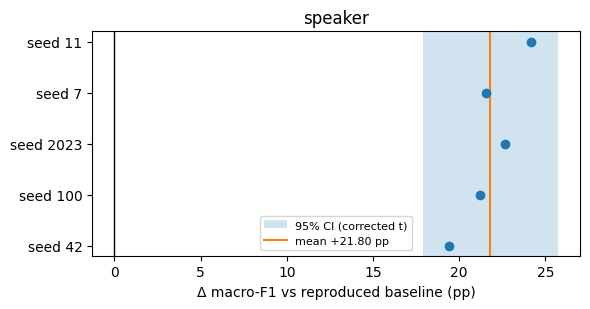

In [21]:
# Forest plot: per-seed paired macro-F1 gain (primary comparison)
fig, axes = plt.subplots(1, len(MODES), figsize=(6 * len(MODES), 3.2), squeeze=False)
for ax, MODE in zip(axes[0], MODES):
    res = STATS[MODE]["comparisons"][P.COMPARISONS[0][2]]
    d = res["per_seed"]["d_f1"].values; s = res["summary"]["f1"]
    ax.scatter(d, range(len(d)), zorder=3); ax.axvline(0, color="k", lw=1)
    ax.axvspan(s["ci_lo"], s["ci_hi"], alpha=.2, label="95% CI (corrected t)")
    ax.axvline(s["delta"], color="C1", label=f"mean {s['delta']:+.2f} pp")
    ax.set_yticks(range(len(d))); ax.set_yticklabels([f"seed {x}" for x in res["per_seed"]["seed"]])
    ax.set_xlabel("Δ macro-F1 vs reproduced baseline (pp)"); ax.set_title(MODE); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{WORKDIR}/forest_primary.png", dpi=150); plt.show()

## Step 6 - claim gate and report

In [22]:
checks = []
def chk(name, ok, detail=""):
    checks.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))

chk("full profile (QUICK=False)", not QUICK)
chk(f"all {CFG['expected_files']} CREMA-D clips used", len(df) == CFG["expected_files"], f"n={len(df)}, unreadable={N_BAD}")
chk(f">= {CFG['min_seeds_for_claim']} seeds", len(CFG["seeds"]) >= CFG["min_seeds_for_claim"], f"seeds={CFG['seeds']}")
chk("primary speaker-independent mode was run", PRIMARY_MODE in MODES)
chk("every seed has paired predictions for every comparison",
    all(len(r["per_seed"]) == len(CFG["seeds"]) for m in MODES for r in STATS[m]["comparisons"].values()))
chk("speaker-disjoint train/test (asserted in make_split)", "speaker" in MODES)
chk("random-split caveat acknowledged (speaker/sentence leakage)", True, "report speaker mode as the headline")
checks_df = pd.DataFrame(checks); display(checks_df)
ok = (checks_df.result == "PASS").all()

REPORT = P.claim_report(STATS, PRIMARY_MODE, ok)
n_test_evals = sum(1 for r in store.rows if "acc" in r)
REPORT += (f"\n\nProtocol notes: {n_test_evals} configurations had test predictions recorded; every selection used validation scores only. "
           "The paper's numbers were not re-run and its split/features are unverified, so 'vs PAPER' lines are descriptive, not a paired test.")
print(REPORT)
open(f"{WORKDIR}/claim_report.txt", "w").write(REPORT)

,check,result,detail
0,full profile (QUICK=False),PASS,
1,all 7442 CREMA-D clips used,PASS,"n=7442, unreadable=0"
2,>= 5 seeds,PASS,"seeds=[42, 100, 2023, 7, 11]"
3,primary speaker-independent mode was run,PASS,
4,every seed has paired predictions for every co...,PASS,
5,speaker-disjoint train/test (asserted in make_...,PASS,
6,random-split caveat acknowledged (speaker/sent...,PASS,report speaker mode as the headline


CLAIMABLE (all checks passed)
[speaker] PRIMARY (speaker-independent)
  vs reproduced baseline: macro-F1 73.45±2.00 vs 51.65±1.50; paired Δ = +21.80 pp (95% CI [+17.88, +25.72], corrected t-test p=0.0001 [significant], positive in 5/5 seeds, actor-bootstrap CI [+20.45, +23.16]).
  vs reproduced baseline: accuracy 73.37±1.95 vs 52.26±1.50; paired Δ = +21.10 pp (95% CI [+17.48, +24.72], corrected t-test p=0.0001 [significant], positive in 5/5 seeds, actor-bootstrap CI [+19.75, +22.44]).
  vs paper-style pipeline: macro-F1 73.45±2.00 vs 52.11±1.48; paired Δ = +21.34 pp (95% CI [+17.94, +24.73], corrected t-test p=0.0001 [significant], positive in 5/5 seeds, actor-bootstrap CI [+20.00, +22.76]).
  vs representation-only: macro-F1 73.45±2.00 vs 70.31±2.67; paired Δ = +3.14 pp (95% CI [-0.11, +6.38], corrected t-test p=0.0551 [not significant], positive in 5/5 seeds, actor-bootstrap CI [+2.28, +4.02]).
  vs PAPER's published macro-F1 (59.8, not re-run, protocol unverified): our mean 73.45 (9

1394

              precision    recall  f1-score   support

       Anger      0.837     0.850     0.843      1957
     Disgust      0.699     0.687     0.693      1957
        Fear      0.666     0.634     0.650      1957
   Happiness      0.763     0.750     0.756      1957
     Neutral      0.788     0.852     0.819      1674
     Sadness      0.648     0.646     0.647      1957

    accuracy                          0.734     11459
   macro avg      0.733     0.737     0.735     11459
weighted avg      0.732     0.734     0.733     11459



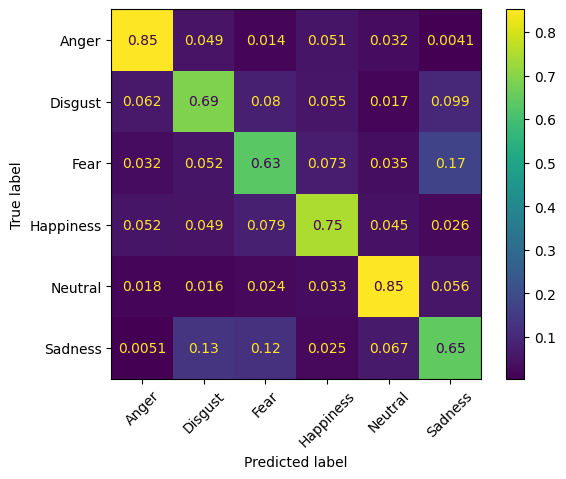

which model won per seed (primary mode): [(42, 'MLP (PyTorch)', 'WavLM-base+'), (100, 'MLP (PyTorch)', 'WavLM-base+'), (2023, 'MLP (PyTorch)', 'WavLM-base+'), (7, 'MLP (PyTorch)', 'Handcrafted + WavLM'), (11, 'MLP (PyTorch)', 'Handcrafted + WavLM')]


In [23]:
# Confusion matrix / per-class report of the final model, pooled over seeds (primary mode)
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
yt, yp = [], []
for s in CFG["seeds"]:
    sp = R.split(s, PRIMARY_MODE); ch = R.chain(PRIMARY_MODE, s)
    yt.append(y[sp.te]); yp.append(R.load_pred(ch["final"]["key"]))
yt, yp = np.concatenate(yt), np.concatenate(yp)
print(classification_report(yt, yp, target_names=le.classes_, digits=3))
ConfusionMatrixDisplay.from_predictions(yt, yp, display_labels=le.classes_, xticks_rotation=45, normalize="true")
plt.savefig(f"{WORKDIR}/confusion_final_{PRIMARY_MODE}.png", dpi=150, bbox_inches="tight"); plt.show()
print("which model won per seed (primary mode):",
      [(s, R.chain(PRIMARY_MODE, s)["final"]["classifier"], R.chain(PRIMARY_MODE, s)["final"]["feature_extraction"].split(" (")[0]) for s in CFG["seeds"]])

In [24]:
# Save everything needed to reproduce / audit
pk = ["numpy", "pandas", "scikit-learn", "scipy", "xgboost", "lightgbm", "catboost", "optuna", "librosa", "torch", "transformers"]
ver = {}
for p_ in pk:
    try: ver[p_] = md_.version(p_)
    except Exception: ver[p_] = None
try:
    import torch; gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except Exception:
    gpu_name = None
json.dump(dict(CFG=CFG, QUICK=QUICK, MODES=MODES, PRIMARY_MODE=PRIMARY_MODE, n_files=len(df), fingerprint=FP,
               versions=ver, python=platform.python_version(), gpu=gpu_name, classes=list(le.classes_),
               claimable=bool(ok)), open(f"{WORKDIR}/config.json", "w"), indent=2, default=str)
store.df().to_csv(f"{WORKDIR}/all_runs.csv", index=False)
print("saved in", WORKDIR); print(sorted(os.listdir(WORKDIR)))

saved in /content/drive/MyDrive/ser_cremad_claim_optimized
['ablation_speaker.csv', 'all_runs.csv', 'claim_report.txt', 'config.json', 'confusion_final_speaker.png', 'emb_w2v2_ee38216880.npy', 'emb_wavlm_ee38216880.npy', 'forest_primary.png', 'hc_ee38216880.npy', 'metadata.csv', 'models', 'per_seed_primary_speaker.csv', 'preds', 'results.json', 'stats_speaker.csv']


## How to word the result (pick what the gate allows)

* **Primary comparison significant (Holm p < 0.05, CI excludes 0, Δ>0 in all seeds):** "Under a speaker-independent protocol on full CREMA-D (5 seeds), our pipeline improves macro-F1 over a reproduced XGBoost/handcrafted baseline by Δ pp (95% CI …, corrected resampled t-test p = …)."
* **Versus the paper's 60.0 / 59.8:** only say "exceeds" if the printed verdict is `above`; otherwise say "comparable to the reported values". Always add "paper figures taken from the publication; split and features not verified to match."
* **Attribution:** use the ablation and the *final vs representation-only* row. If selection and tuning add nothing significant, attribute the gain to the self-supervised representation, not to the explainability-guided selection.
* **Never** report the best of many test-evaluated variants; the final model is whatever the validation-based chain picks.

## Limitations
* Seeds re-use the same recordings, so the corrected t-test (not a plain t-test) is used; with 5 seeds it has df = 4 and modest power. Use 10 seeds if you need tighter intervals.
* Exact McNemar treats clips as independent; actor-level bootstrap and the seed-level test are the primary evidence.
* GPU XGBoost / CatBoost are not bit-wise deterministic; fixed seeds make runs close, not identical.
* CREMA-D labels are perceived emotion from acted speech; results do not transfer to spontaneous speech.
* Validation-based choice of MLP vs trees favours trees slightly (their hyper-parameters were optimised on the same validation split), which is conservative for the MLP.